# Linear algebra 1: Vectors and matrices

*Learning path: linear algebra, part 1 of 9.* [Index](README.md) · Previous: [Simplify and eval](00-simplify-and-eval.ipynb) · Next: [Linear systems](02-linear-systems.ipynb)

A computer game turns a 3D world into the picture on your screen; a phone straightens a photo of a page; a robot arm
works out where its hand is from the angles of its joints. All three do the same thing millions of times a second:
multiply a **matrix** by a **vector**. This lesson is about what that multiplication means, and why it is always the
same kind of transformation: one that keeps straight lines straight and the origin in place.

**Who this is for.** You know coordinates in the plane, Pythagoras and the sine and cosine
([foundations](../foundations/README.md) up to trigonometry). Nothing else.

**What you will be able to do afterwards:**

1. add and scale vectors, and compute lengths, dot products and angles;
2. read a matrix as a transformation: its columns are where the unit arrows go;
3. multiply matrices, and explain why $AB$ means "first $B$, then $A$";
4. find the matrix of a rotation, a reflection, a shear, and undo one with the inverse.

Plan about an hour.

## 1. Vectors

A vector in the plane is an arrow, written as its two components: $u = [3\ 4]$ goes 3 to the right and 4 up. Vectors
are added component by component (put the arrows head to tail) and multiplied by numbers (stretch the arrow):

In [1]:
u = [3 4];
v = [4 -2];
u + v
2*u
u - v

[7, 2]
[6, 8]
[-1, 6]

The plot draws $u$, $v$ and $u + v$ as arrows from the origin. Each arrow is a straight segment
`parametric(s*a, s*b, s, 0, 1)`: the points $s\cdot[a\ b]$ for $s$ from 0 to 1. The axes are the two components.

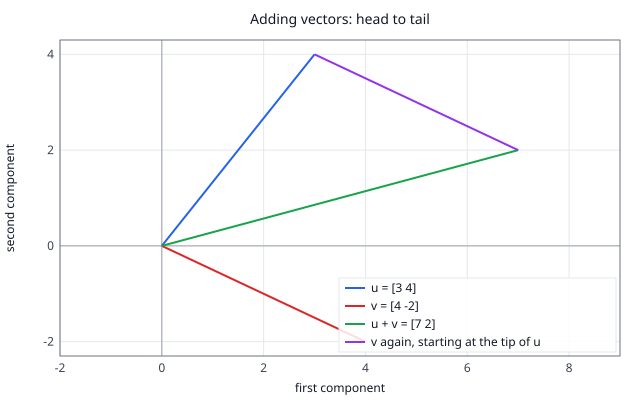

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [2]:
p = show(parametric(3*s, 4*s, s, 0, 1), parametric(4*s, -2*s, s, 0, 1), parametric(7*s, 2*s, s, 0, 1), parametric(3 + 4*s, 4 - 2*s, s, 0, 1));
p = legend(p, "u = [3 4]", "v = [4 -2]", "u + v = [7 2]", "v again, starting at the tip of u");
labels(title(p, "Adding vectors: head to tail"), "first component", "second component")

A sum of multiples, $a u + b v$, is a **linear combination** of $u$ and $v$. Here is a question that will run through
the whole course: *which vectors can you reach as linear combinations?* With $u = [3\ 4]$ and $v = [4\ {-2}]$, can you
reach $[1\ 0]$? That needs $3a + 4b = 1$ and $4a - 2b = 0$, two equations for two unknowns:

In [3]:
solve([3*a + 4*b == 1, 4*a - 2*b == 0], [a, b])

[1/11, 2/11]

> `solve`: Solves f = 0 (or an equation lhs == rhs) for x and returns all solutions in a row.

So $[1\ 0] = \tfrac{1}{11}u + \tfrac{2}{11}v$. In fact every vector of the plane is a combination of these two, because
they point in different directions. Two arrows on one line, like $[1\ 2]$ and $[2\ 4]$, only reach that line.

**Try this.** Write $[0\ 1]$ as a combination of $u$ and $v$, first by hand, then with `solve`.

## 2. Length, dot product and angle

The **length** of $[a\ b]$ is $\sqrt{a^2 + b^2}$ (Pythagoras), computed by `norm`. The **dot product** multiplies
matching components and adds: $u\cdot v = u_1v_1 + u_2v_2$. It measures how much two arrows point the same way:

$$u \cdot v = |u|\,|v|\cos\theta,$$

where $\theta$ is the angle between them. So $\cos\theta = \dfrac{u\cdot v}{|u|\,|v|}$, and a dot product of 0 means
the arrows are **perpendicular** (orthogonal):

In [4]:
norm(u)
dot(u, v)
dot(u, [4 -3])
eval(acos(dot(u, v)/(norm(u)*norm(v)))*180/pi)

5

> `norm`: Matrix norms: 2-norm (largest singular value, the default), 1-norm (largest column sum), inf-norm (largest row sum), Frobenius.

4

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

79.69515353123397

> `eval`: Evaluates an expression numerically, for example a fraction or a constant like pi.

$[3\ 4]$ has length 5, $[3\ 4]$ and $[4\ {-3}]$ are perpendicular, and $u$ and $v$ make an angle of about $79.7^\circ$.
Why does the formula hold? Expand $|u - v|^2 = (u - v)\cdot(u - v) = |u|^2 + |v|^2 - 2\,u\cdot v$ and compare with the
law of cosines for the triangle with sides $u$, $v$, $u - v$: $|u - v|^2 = |u|^2 + |v|^2 - 2|u||v|\cos\theta$.

Everything works the same in three dimensions (or a thousand) with more components. In 3D, `cross(a, b)` gives a
vector perpendicular to both $a$ and $b$, with length equal to the area of the parallelogram they span:

In [5]:
cross([1 0 0], [0 1 0])
cross([1 2 3], [4 5 6])
dot(cross([1 2 3], [4 5 6]), [1 2 3])

[0, 0, 1]

> `cross` (see `dot`): Dot product of two vectors, and cross product of two vectors of length 3.

[-3, 6, -3]

> `cross` (see `dot`): Dot product of two vectors, and cross product of two vectors of length 3.

0

> `dot`: Dot product of two vectors, and cross product of two vectors of length 3.

A vector of length 1 is a **unit vector**. Divide any nonzero vector by its length to get one: `u/norm(u)` is
$[3/5\ \ 4/5]$.

**Try this.** Find the angle between the diagonal of a cube, $[1\ 1\ 1]$, and one of its edges, $[1\ 0\ 0]$. (By hand:
$\cos\theta = 1/\sqrt3$.)

## 3. Matrices transform the plane

A $2\times2$ matrix $A$ turns a vector $x$ (written as a column) into another vector $Ax$: each component of $Ax$ is
the dot product of a row of $A$ with $x$.

In [6]:
A = [2 1; 1 2];
A*[1; 0]
A*[0; 1]
A*[3; -1]

[2;
 1]
[1;
 2]
[5;
 1]

The images of $[1\ 0]$ and $[0\ 1]$ are the **columns** of $A$. That is all you need to know about a linear
transformation: since $x = x_1[1\ 0] + x_2[0\ 1]$, its image is

$$Ax = x_1\cdot(\text{column 1}) + x_2\cdot(\text{column 2}),$$

a linear combination of the columns. Check: $3\cdot[2\ 1] - 1\cdot[1\ 2] = [5\ 1]$. This "column picture" is worth
more than the row-times-column rule, and we will use it again and again.

To see what $A$ does to the whole plane, look at what it does to the unit circle, the points $[\cos t\ \sin t]$. `w`
is the image of the circle point at angle $t$; `w(1)` and `w(2)` are its two components:

In [7]:
w = A*[cos(t); sin(t)]

[sin(t)+2*cos(t);
 2*sin(t)+cos(t)]

The plot shows the unit circle and its image, an ellipse, with the images of the two unit arrows. Axes: the two
coordinates of the plane. `parametric(X, Y, t, 0, 2*pi)` draws the point $(X, Y)$ for $t$ from 0 to $2\pi$:

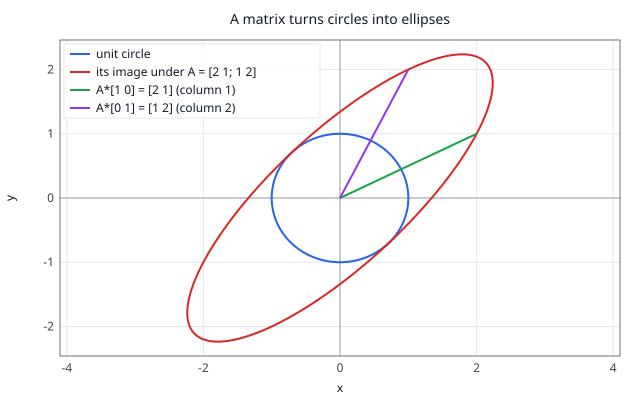

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [8]:
p = show(parametric(cos(t), sin(t), t, 0, 2*pi), parametric(w(1), w(2), t, 0, 2*pi), parametric(2*s, s, s, 0, 1), parametric(s, 2*s, s, 0, 1));
p = legend(p, "unit circle", "its image under A = [2 1; 1 2]", "A*[1 0] = [2 1] (column 1)", "A*[0 1] = [1 2] (column 2)");
labels(title(p, "A matrix turns circles into ellipses"), "x", "y")

The ellipse is stretched most along the diagonal $y = x$ and least along $y = -x$. Those two directions are special:
there $A$ only stretches without turning. They are the **eigenvectors** of [lesson 6](06-eigenvalues.ipynb).

Why do lines stay lines? A line is $p + s\,d$; its image is $A(p + s\,d) = Ap + s\,Ad$, again a line. That property,
$A(au + bv) = aAu + bAv$, is what **linear** means.

**Try this.** Without computing, predict where $A$ sends $[1\ 1]$ and $[1\ {-1}]$. Then check.

## 4. A gallery of transformations

Since the columns are the images of $[1\ 0]$ and $[0\ 1]$, you can write down a matrix by drawing where those two arrows
go.

* **Rotation** by an angle $t$: $[1\ 0]$ goes to $[\cos t\ \sin t]$, and $[0\ 1]$ to $[-\sin t\ \cos t]$.
* **Reflection** in the $x$-axis: $[1\ 0]$ stays, $[0\ 1]$ flips to $[0\ {-1}]$.
* **Shear**: $[1\ 0]$ stays, $[0\ 1]$ leans over to $[1\ 1]$, like a deck of cards pushed sideways.
* **Projection** onto the $x$-axis: $[1\ 0]$ stays, $[0\ 1]$ is flattened to $[0\ 0]$.

In [9]:
R = [cos(t), -sin(t); sin(t), cos(t)];
F = [1 0; 0 -1];
H = [1 1; 0 1];
Px = [1 0; 0 0];
subs(R, t, pi/2)*[1; 0]
F*[2; 3]
H*[2; 3]
Px*[2; 3]

[0;
 1]
[ 2;
 -3]
[5;
 3]
[2;
 0]

(In `R` the entries are separated by commas, because inside brackets a space followed by a minus sign starts a new
entry.)

To draw what they do, follow the outline of the unit square. `c(z)` clamps $z$ to the interval $[0, 1]$ (written with
`abs` so that it works in a formula), and as $s$ runs from 0 to 4 the point `sq` walks once around the square:
right along the bottom, up, back along the top, down. `M*sq` is the image of that walk under a matrix $M$. Axes: the
coordinates $x$ and $y$.

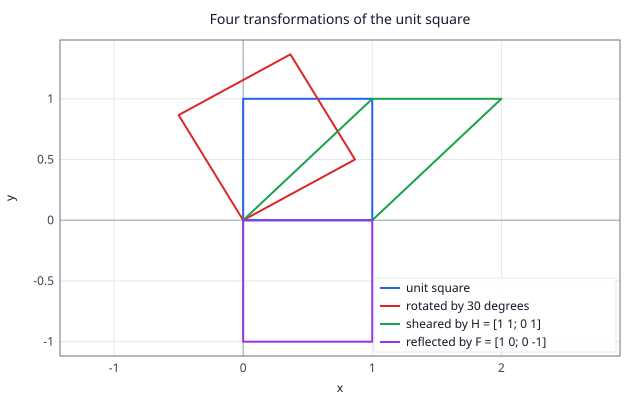

> `labels` (see `title`): A copy of plot p with a title or axis labels.

In [10]:
c(z) := (abs(z) - abs(z - 1) + 1)/2;
sq = [c(s) - c(s - 2); c(s - 1) - c(s - 3)];
r = subs(R, t, pi/6)*sq;
h = H*sq;
f = F*sq;
p = show(parametric(sq(1), sq(2), s, 0, 4), parametric(r(1), r(2), s, 0, 4), parametric(h(1), h(2), s, 0, 4), parametric(f(1), f(2), s, 0, 4));
p = legend(p, "unit square", "rotated by 30 degrees", "sheared by H = [1 1; 0 1]", "reflected by F = [1 0; 0 -1]");
labels(title(p, "Four transformations of the unit square"), "x", "y")

The rotation and the reflection keep the shape; the shear turns the square into a parallelogram with the same base
and height (so the same area). The projection would flatten it to the segment from 0 to 1 on the $x$-axis.

**Try this.** Write down the matrix that reflects the plane in the line $y = x$. (Where do $[1\ 0]$ and $[0\ 1]$ go?)
Apply it to $[2\ 5]$.

## 5. Multiplying matrices

Doing transformation $B$ and then $A$ is again a linear transformation, with matrix $AB$ (the **product**). Its
columns are $A$ times the columns of $B$; equivalently, entry $(i, j)$ is the dot product of row $i$ of $A$ with
column $j$ of $B$. Rotating by $s$ and then by $t$ is rotating by $s + t$, and the product shows the addition formulas
of trigonometry:

In [11]:
Rs = [cos(s), -sin(s); sin(s), cos(s)];
R*Rs

[cos(s)*cos(t)-sin(s)*sin(t), -sin(s)*cos(t)-cos(s)*sin(t);
 sin(s)*cos(t)+cos(s)*sin(t),  cos(s)*cos(t)-sin(s)*sin(t)]

The top left entry is $\cos s\cos t - \sin s \sin t = \cos(s + t)$, the bottom left $\sin(s + t)$. Order matters:
$AB \ne BA$ in general. Shearing then reflecting is not reflecting then shearing:

In [12]:
F*H
H*F

[1,  1;
 0, -1]
[1, -1;
 0, -1]

Some rules, all following from "first $B$, then $A$": $(AB)C = A(BC)$ (you may regroup); $A(B + C) = AB + AC$; and the
**identity** $I$ = `eye(n)`, which leaves every vector alone, has $AI = IA = A$. Powers repeat a transformation:
three shears push three times as far.

In [13]:
H^3

[1, 3;
 0, 1]

**Try this.** Compute $F^2$ for the reflection. Explain the answer without computing. Then guess $R^n$ for the
rotation.

## 6. Undoing a transformation: the inverse

The **inverse** $A^{-1}$ undoes $A$: $A^{-1}A = AA^{-1} = I$. Undoing a shear is shearing back; undoing a rotation by
$t$ is rotating by $-t$:

In [14]:
inv(H)
inv(A)
inv(A)*A
simplify(inv(R))

[1, -1;
 0,  1]

> `inv`: Inverse of a matrix; works with symbolic entries.

[ 2/3, -1/3;
 -1/3,  2/3]

> `inv`: Inverse of a matrix; works with symbolic entries.

[1, 0;
 0, 1]

[ cos(t), sin(t);
 -sin(t), cos(t)]

> `simplify`: simplify(expr) writes expr in one fixed form: a fraction N/D of multiplied-out polynomials (in the symbols, constants and functions of expr) with common factors cancelled, square roots moved out of denominators, and sin^2 + cos^2 = 1 used in whichever direction is shorter.

For a $2\times2$ matrix there is a formula you should know by heart:

$$\begin{pmatrix} a & b\\ c & d\end{pmatrix}^{-1} = \frac{1}{ad - bc}\begin{pmatrix} d & -b\\ -c & a\end{pmatrix}.$$

In [15]:
inv([a b; c d])

[d/(a*d-b*c), b/(b*c-a*d);
 c/(b*c-a*d), a/(a*d-b*c)]

> `inv`: Inverse of a matrix; works with symbolic entries.

It fails when $ad - bc = 0$. Then the matrix squashes the plane onto a line (or a point), and no matrix can undo
that: the projection `Px` sent both $[2\ 3]$ and $[2\ 0]$ to $[2\ 0]$; which one should the inverse return? The
number $ad - bc$ is the **determinant**, the subject of [lesson 4](04-determinants.ipynb).

The inverse of a product reverses the order, $(AB)^{-1} = B^{-1}A^{-1}$, like taking off socks and shoes: what went on
last comes off first.

**Try this.** Find the inverse of $[2\ 1;\ 5\ 3]$ with the formula, then check with `inv`.

## Exercises

1. **Combinations.** Is $[1\ 2\ 3]$ a linear combination of $[1\ 0\ 1]$ and $[0\ 1\ 1]$? Is $[1\ 2\ 4]$?
2. **Angles.** Find a nonzero vector perpendicular to both $[1\ 1\ 0]$ and $[0\ 1\ 1]$ in two ways: with `cross`, and by
   solving two equations $x\cdot a = 0$, $x\cdot b = 0$.
3. **Build a matrix.** Find the matrix that first rotates by $90^\circ$ and then reflects in the $x$-axis. Which single
   reflection is it?
4. **Powers.** Compute $R^2$ for the rotation $R$ and simplify; which angle does it rotate by? What is $R^{12}$ for
   $t = \pi/6$?
5. **No inverse.** Show that $[1\ 2;\ 2\ 4]$ has no inverse, and find two different vectors that it sends to the same
   place.

## Hints and answers

* **Section 1, Try this.** $3a + 4b = 0$, $4a - 2b = 1$ gives $a = 2/11$, $b = -3/22$.
* **Section 2, Try this.** $\cos\theta = 1/\sqrt3$, $\theta \approx 54.7^\circ$: `eval(acos(1/sqrt(3))*180/pi)`.
* **Section 3, Try this.** $A[1\ 1] = [3\ 3]$ (stretched by 3) and $A[1\ {-1}] = [1\ {-1}]$ (unchanged): the two
  special directions.
* **Section 4, Try this.** $[0\ 1;\ 1\ 0]$; it sends $[2\ 5]$ to $[5\ 2]$.
* **Section 5, Try this.** $F^2 = I$: reflecting twice puts everything back. $R^n$ rotates by $nt$:
  $[\cos nt, -\sin nt;\ \sin nt, \cos nt]$.
* **Section 6, Try this.** $ad - bc = 1$, inverse $[3\ {-1};\ {-5}\ 2]$.
* **Exercise 1.** $a[1\ 0\ 1] + b[0\ 1\ 1] = [a\ \ b\ \ a + b]$, so the third entry must be the sum of the first two:
  $[1\ 2\ 3]$ yes ($a = 1$, $b = 2$), $[1\ 2\ 4]$ no.
* **Exercise 2.** `cross([1 1 0], [0 1 1])` $= [1\ {-1}\ 1]$; `solve([x + y == 0, y + z == 0], [x, y])` leaves $z$ free
  and gives the same direction.
* **Exercise 3.** `F*subs(R, t, pi/2)` $= [0\ {-1};\ {-1}\ 0]$: reflection in the line $y = -x$.
* **Exercise 4.** `simplify(R*R)` rotates by $2t$; for $t = \pi/6$, $R^{12}$ is a full turn, $I$.
* **Exercise 5.** $ad - bc = 4 - 4 = 0$. It sends $[2\ 0]$ and $[0\ 1]$ both to $[2\ 4]$: the columns lie on one line.

## Sources

1. G. Strang, *Introduction to Linear Algebra*, 6th ed., Wellesley-Cambridge Press (2023), chapters 1 and 2.
2. D. C. Lay, S. R. Lay and J. J. McDonald, *Linear Algebra and Its Applications*, 6th ed., Pearson (2021), chapter 1.
3. S. Axler, *Linear Algebra Done Right*, 4th ed., Springer (2024), open access, chapters 1 to 3.
4. 3Blue1Brown, *Essence of Linear Algebra* (video series, 2016), chapters 1 to 4.